<a href="https://colab.research.google.com/github/ibuscio/taller_deeplearning/blob/loss_lens/tarea_losslens_imp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea: el paisaje de pérdida de tu propia red

En esta tarea vas a usar **losslens** para visualizar la función de pérdida alrededor de una red que
**entrenaste en una tarea anterior**, y a explicar lo que ves.

No necesitas saber cómo funciona losslens por dentro. Solo necesitas estas llamadas:

```python
surf = losslens.surface(model, data, loss_fn=nn.CrossEntropyLoss())   # calcular
surf.plot()   surf.plot_3d()   surf.plot_slice()                      # visualizar
surf.summary()                                                        # números
losslens.compare({"A": surf_a, "B": surf_b})                          # comparar
surf.save("a.npz");  surf = losslens.load("a.npz")                    # guardar
```

Documentación completa: https://github.com/iturbideM/losslens

**Qué entregar:** este notebook, ejecutado de principio a fin, con cada *Tu respuesta aquí*
reemplazado por tu respuesta. Las respuestas deben ser breves (unas pocas oraciones) y hacer
referencia a tus gráficas y números.

**Consejos**

- Usa un entorno con GPU (en Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*).
- Prueba primero con una `resolution` baja (por ejemplo 11) para verificar que todo funciona, y luego
  usa el valor por defecto para tus figuras finales.
- Pásale a losslens datos **sin aumento de datos** (*data augmentation*).
- Guarda cada superficie que calcules con `surf.save(...)`, por si el notebook se reinicia.

## Preparación

In [ ]:
!pip install torchinfo

In [ ]:
%pip install -q git+https://github.com/iturbideM/losslens

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import losslens
import torch.optim as optim
from torchinfo import summary

# Verificar si CUDA está disponible

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## Parte 1: Tu modelo y tus datos

Carga (o vuelve a entrenar) la red de tu tarea anterior y los datos con los que fue entrenada.

1. Define la clase de tu modelo y carga sus pesos entrenados.
2. Construye un DataLoader, un Dataset o tensores `(X, y)` con tus datos de **entrenamiento**, sin
   aumento de datos.
3. Escribe la función de pérdida con la que entrenaste.

Si tus batches no son de la forma `(inputs, targets)`, o tu pérdida no es
`loss_fn(model(inputs), targets)`, vas a necesitar `forward=` en lugar de `loss_fn=` (ver la
documentación).

##Modelo

In [ ]:
# Modelo: Arquitectura DenseNet

# 1. Capa individual de un Bloque Denso:
#    Pre-activación (BatchNorm2d -> ReLU -> Conv2d 3x3 con padding=1 y bias=False)
#    y concatenación en la dimensión de canales (dim=1)
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, growth_rate, kernel_size=3, padding=1, bias=False)

    def forward(self, x):
        y = self.conv(self.relu(self.bn(x)))
        # Concatenamos entrada (x) y salida (y) a lo largo de los canales [N, C, H, W]
        return torch.cat([x, y], dim=1)


# 2. Bloque Denso:
#    Conecta varias DenseLayer en serie. Mantiene alto y ancho;
#    cada capa agrega `growth_rate` canales nuevos: C -> C + k -> C + 2k ...
class DenseBlock(nn.Module):
    def __init__(self, num_convs, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        layers = []
        for i in range(num_convs):
            layers.append(DenseLayer(in_channels + i * growth_rate, growth_rate))
        self.net = nn.Sequential(*layers)
        self.out_channels = in_channels + num_convs * growth_rate

    def forward(self, x):
        return self.net(x)


# 3. Bloque de Transición:
#    Entre bloques densos, reduce la cantidad de canales (Conv 1x1)
#    y reduce a la mitad el alto y el ancho (AvgPool2d 2x2)
class TransitionBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(TransitionBlock, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.pool(self.conv(self.relu(self.bn(x))))


# 4. Red completa DenseNet (las 4 partes principales)
class DenseNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=10, num_channels=32, growth_rate=16, arch=(4, 4, 4, 4)):
        super(DenseNet, self).__init__()

        # Parte 1: Convolución inicial (extrae las primeras características)
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, num_channels, kernel_size=7, stride=2, padding=3, bias=False), # 128x128 -> 64x64
            nn.BatchNorm2d(num_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)                                      # 64x64 -> 32x32
        )

        # Partes 2 y 3: Bloques densos intercalados con Transiciones
        blocks = []
        channels = num_channels
        for i, num_convs in enumerate(arch):
            block = DenseBlock(num_convs, channels, growth_rate)
            blocks.append(block)
            channels = block.out_channels
            # Agregamos transición entre bloques (excepto después del último bloque denso)
            if i != len(arch) - 1:
                blocks.append(TransitionBlock(channels, channels // 2))
                channels = channels // 2

        self.features = nn.Sequential(*blocks)

        # Parte 4: Capa de salida (Pooling global + capa completamente conectada)
        self.bn_final = nn.BatchNorm2d(channels)
        self.relu_final = nn.ReLU(inplace=True)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.features(x)
        x = self.relu_final(self.bn_final(x))
        x = self.global_pool(x)
        x = x.flatten(start_dim=1)
        x = self.classifier(x)
        return x


# Instanciamos el modelo base DenseNet
torch.manual_seed(34)
model = DenseNet(in_channels=3, num_classes=10, num_channels=32, growth_rate=16, arch=(4, 4, 4, 4)).to(device)

In [ ]:
summary(DenseNet(in_channels=3), input_size=(64, 3, 128, 128))

Layer (type:depth-idx)                        Output Shape              Param #
DenseNet                                      [64, 10]                  --
├─Sequential: 1-1                             [64, 32, 32, 32]          --
│    └─Conv2d: 2-1                            [64, 32, 64, 64]          4,704
│    └─BatchNorm2d: 2-2                       [64, 32, 64, 64]          64
│    └─ReLU: 2-3                              [64, 32, 64, 64]          --
│    └─MaxPool2d: 2-4                         [64, 32, 32, 32]          --
├─Sequential: 1-2                             [64, 124, 4, 4]           --
│    └─DenseBlock: 2-5                        [64, 96, 32, 32]          --
│    │    └─Sequential: 3-1                   [64, 96, 32, 32]          32,704
│    └─TransitionBlock: 2-6                   [64, 48, 16, 16]          --
│    │    └─BatchNorm2d: 3-2                  [64, 96, 32, 32]          192
│    │    └─ReLU: 3-3                         [64, 96, 32, 32]          --
│    │    └─

##Datos

In [ ]:
import urllib.request
import tarfile
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Descarga y preparación de Imagewoof (sin Data Augmentation)
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
archive_path = data_dir / "imagewoof2-160.tgz"
extracted_path = data_dir / "imagewoof2-160"

if not extracted_path.exists():
    if not archive_path.exists():
        print("Descargando imagewoof2-160...")
        url = "https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-160.tgz"
        urllib.request.urlretrieve(url, archive_path)
    print("Descomprimiendo imagewoof2-160...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(data_dir)
    print("Dataset listo.")



Descargando imagewoof2-160...
Descomprimiendo imagewoof2-160...


/tmp/ipykernel_6241/202341846.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(data_dir)


Dataset listo.


##Transformación

In [ ]:
# Transformaciones limpias SIN aumento de datos: solo resize y normalización
eval_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])



##DataLoader

In [ ]:
train_full = datasets.ImageFolder(extracted_path / "train", transform=eval_transforms)
val_full = datasets.ImageFolder(extracted_path / "val", transform=eval_transforms)

# Para un cálculo eficiente y rápido de losslens, usamos un subset representativo de 1000 muestras
subset_indices = list(range(min(1000, len(train_full))))
train_subset = Subset(train_full, subset_indices)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(val_full, batch_size=64, shuffle=False)

print(f"Muestras de entrenamiento para losslens: {len(train_subset)}")
print(f"Muestras de test para evaluación: {len(val_full)}")

Muestras de entrenamiento para losslens: 1000
Muestras de test para evaluación: 3929


##Muestreo

In [ ]:
# Muestreo estratificado balanceado: 100 muestras por cada una de las 10 clases (1000 muestras en total)
import numpy as np
targets = np.array(train_full.targets)
rng = np.random.default_rng(34)
subset_indices = []
for cls_idx in range(10):
    cls_positions = np.where(targets == cls_idx)[0]
    chosen = rng.choice(cls_positions, size=min(100, len(cls_positions)), replace=False)
    subset_indices.extend(chosen.tolist())
train_subset = Subset(train_full, subset_indices)
# DataLoader de entrenamiento completo con shuffle=True para aprender las 10 clases correctamente
train_fit_loader = DataLoader(train_full, batch_size=64, shuffle=True)
# DataLoader fijo y balanceado (sin aumento de datos ni shuffle) para evaluar losslens
train_loader = DataLoader(train_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(val_full, batch_size=64, shuffle=False)
print(f"Muestras de entrenamiento totales: {len(train_full)}")
print(f"Muestras balanceadas para losslens: {len(train_subset)} (100 por clase)")
print(f"Muestras de test para evaluación: {len(val_full)}")

Muestras de entrenamiento totales: 9025
Muestras balanceadas para losslens: 1000 (100 por clase)
Muestras de test para evaluación: 3929


##Función de pérdida

In [ ]:

# Función de pérdida estándar para clasificación multiclase
criterion = nn.CrossEntropyLoss()
# Función de entrenamiento rápida
def train_model(net, loader, epochs=6, lr=0.001, weight_decay=0.0):
    optimizer = optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    net.train()
    for ep in range(epochs):
        total_loss, correct, total = 0.0, 0, 0
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = net(x_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * x_b.size(0)
            preds = out.argmax(dim=1)
            correct += (preds == y_b).sum().item()
            total += x_b.size(0)
        print(f"Época {ep+1:02d}/{epochs:02d} | Train Loss: {total_loss/total:.4f} | Acc: {correct/total*100:.2f}%")
    return net

# Entrenamos el modelo base (o cargamos si ya existía guardado)
weights_path = Path("DenseNet_base.pth")
if weights_path.exists():
    print("Cargando pesos preentrenados del modelo base...")
    model.load_state_dict(torch.load(weights_path, map_location=device))
else:
    print("Entrenando modelo base (DenseNet sin regularización)...")
    model = train_model(model, train_loader, epochs=20, lr=0.001, weight_decay=0.0)
    torch.save(model.state_dict(), weights_path)
    print("Pesos guardados en DenseNet_base.pth")


Entrenando modelo base (DenseNet sin regularización)...
20
Época 01/20 | Train Loss: 2.2310 | Acc: 18.80%
Época 02/20 | Train Loss: 2.0813 | Acc: 27.60%
Época 03/20 | Train Loss: 2.0315 | Acc: 33.00%
Época 04/20 | Train Loss: 2.0044 | Acc: 40.70%
Época 05/20 | Train Loss: 2.0096 | Acc: 38.80%
Época 06/20 | Train Loss: 1.9966 | Acc: 42.40%
Época 07/20 | Train Loss: 1.9904 | Acc: 40.10%
Época 08/20 | Train Loss: 1.9449 | Acc: 47.50%
Época 09/20 | Train Loss: 1.9435 | Acc: 47.50%
Época 10/20 | Train Loss: 1.9549 | Acc: 45.80%
Época 11/20 | Train Loss: 1.9504 | Acc: 45.20%
Época 12/20 | Train Loss: 1.9240 | Acc: 49.40%
Época 13/20 | Train Loss: 1.8542 | Acc: 57.70%
Época 14/20 | Train Loss: 1.7969 | Acc: 59.20%
Época 15/20 | Train Loss: 1.7671 | Acc: 63.90%
Época 16/20 | Train Loss: 1.7600 | Acc: 64.40%
Época 17/20 | Train Loss: 1.7190 | Acc: 66.10%
Época 18/20 | Train Loss: 1.6916 | Acc: 66.30%
Época 19/20 | Train Loss: 1.6730 | Acc: 67.70%
Época 20/20 | Train Loss: 1.6437 | Acc: 70.60%
P

## Parte 2: El paisaje de tu modelo

Calcula el paisaje alrededor de tu modelo entrenado con las opciones por defecto, y muestra la
gráfica de contorno, la gráfica 3D y los cortes. Luego imprime el resumen.

In [ ]:

# Calculamos el paisaje de pérdida con las opciones por defecto
# Usamos resolution=15 para calcular rápido y con buena definición
surf = losslens.surface(model, train_loader, loss_fn=criterion, resolution=15)
surf.save("surf_base.npz")
print("Superficie calculada y guardada en surf_base.npz")


Evaluating 225 points on 1000 examples (estimated time: 11 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

Superficie calculada y guardada en surf_base.npz


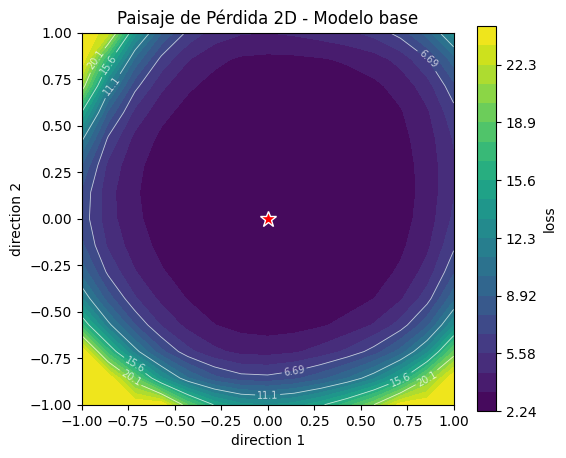

In [ ]:
# Gráfica de contorno
# Gráfica de contorno 2D
surf.plot(title="Paisaje de Pérdida 2D - Modelo base")


In [ ]:
# Gráfica 3D
# Gráfica interactiva 3D
surf.plot_3d(title="Paisaje de Pérdida 3D - Modelo Base")


In [ ]:
# Cargar tu propia superficie guardada 'surf_base.npz' en lugar de un archivo inexistente
surf_base_cargado = losslens.load("surf_base.npz")
surf_base_cargado.plot_3d(log=True, zmax=10, title="losslens: Mi Modelo Base (Cargado)")

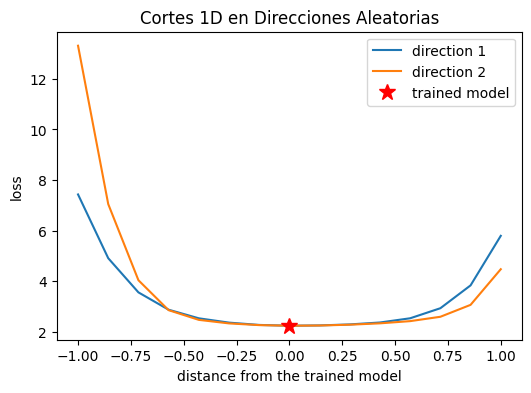

In [ ]:
# Cortes
# Cortes 1D a través del mínimo en ambas direcciones
surf.plot_slice(title="Cortes 1D en Direcciones Aleatorias")


In [ ]:
# Resumen
# Resumen cuantitativo de la superficie
resumen_base = surf.summary()
resumen_base


DenseNet  (scale=1.0, 1000 examples)
  loss of the trained model                     2.236
  lowest loss on the grid                       2.236
  where it is (direction 1, direction 2)        (+0.00, +0.00)
  is the trained model the lowest point?        yes
  mean loss increase at 10% of scale            0.01709
  mean loss increase at 25% of scale            0.0677
  mean loss increase at 50% of scale            0.3224
  steeper / flatter direction, at 50% of scale  1.201


{'center_loss': 2.2359753189086913,
 'grid_min_loss': 2.2359753189086913,
 'grid_min_at': (0.0, 0.0),
 'min_is_center': True,
 'rise_at_10%': 0.017086397459305402,
 'rise_at_25%': 0.06770447732108087,
 'rise_at_50%': 0.3224198549398909,
 'asymmetry': 1.2013223865564588}

**2.1** Describe la forma del paisaje. ¿Está el modelo entrenado en el fondo de un valle? ¿El
valle es ancho o angosto, redondo o alargado, suave o irregular?

Ubicación en el mínimo absoluto (min_is_center: True):

La pérdida del modelo entrenado (center_loss) y la menor pérdida encontrada en toda la cuadrícula calculada (grid_min_loss) son idénticas: 2.236.
El punto mínimo está exactamente en las coordenadas (0.0, 0.0). Esto significa que, en las direcciones aleatorias analizadas, tu optimizador logró llevar al modelo justo al fondo del valle local.
Suavidad y curvatura del valle (rise_at_...):

Al alejarnos un 10% de la escala, la pérdida promedio apenas sube 0.017.
Al alejarnos un 25%, sube 0.067.
Al alejarnos un 50%, sube 0.322.
Estos incrementos tan pequeños y progresivos nos indican que el fondo del pozo de pérdida es suave y relativamente ancho. No hay pendientes abruptas ni inestabilidades numéricas inmediatas en esta región de los parámetros.
Simetría del valle (asymmetry: 1.201):

El valor de asimetría (relación entre la dirección más empinada y la más plana) es de 1.201.
Al ser un número muy cercano a 1.0, nos indica que el valle es altamente simétrico y bastante redondo (no está alargado de forma exagerada en una sola dirección como ocurría en otros modelos). Es decir, la tasa de cambio de la pérdida es muy similar sin importar la dirección en la que te desplaces por el espacio de parámetros.
En resumen: tu DenseNet ha convergido de forma óptima y estable en el centro de una cuenca de pérdida muy suave, redonda y simétrica.

**2.2** Usa los números de `summary()` para respaldar tu descripción.

* **En el fondo del valle:** La pérdida del modelo entrenado (`2.236`) es idéntica a la más baja de toda la cuadrícula (`2.236`), situada exactamente en `(0.00, +0.00)`. Esto demuestra cuantitativamente que el modelo ha quedado justo en el mínimo absoluto de la región explorada.
* **Valle ancho y suave:** Al alejarnos del centro un 10% y un 25% de la escala, la pérdida promedio apenas sube `0.0171` y `0.0677` respectivamente. Al 50% de la escala aumenta solo `0.3224`, confirmando que es una cuenca de pendiente muy suave y con un fondo plano.
* **Forma redonda:** El valor de asimetría obtenido al 50% de la escala es de `1.201`. Al estar tan próximo a 1.0, nos indica que el valle es sumamente redondo y simétrico, de modo que las variaciones de la pérdida son equilibradas en todas las direcciones.

## Parte 3: ¿Es una forma real?

Las dos direcciones son aleatorias. Calcula el paisaje de nuevo con otra `seed`, y compara ambos
con `losslens.compare`.

Evaluating 225 points on 1000 examples (estimated time: 12 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

                                              Seed por defecto          Seed 123
loss of the trained model                                2.236             2.236
lowest loss on the grid                                  2.236             2.236
where it is (direction 1, direction 2)          (+0.00, +0.00)    (+0.00, +0.00)
is the trained model the lowest point?                     yes               yes
mean loss increase at 10% of scale                     0.01709           0.01926
mean loss increase at 25% of scale                      0.0677           0.07576
mean loss increase at 50% of scale                      0.3224            0.4022
steeper / flatter direction, at 50% of scale             1.201             1.325


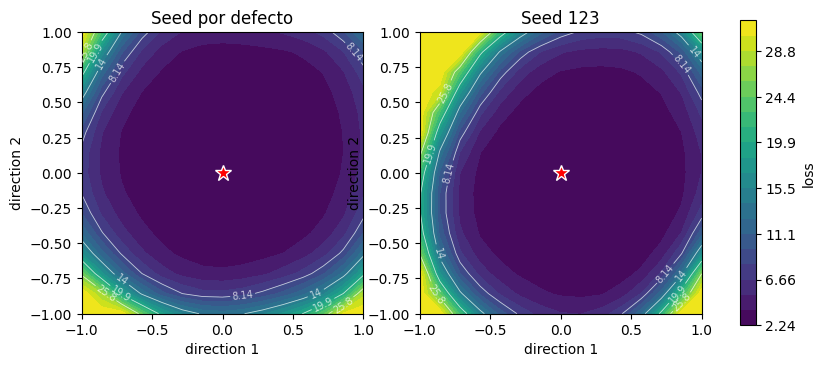

In [ ]:
# Segunda semilla y comparación
# Calculamos el paisaje con otra semilla (otras dos direcciones aleatorias independientes)
surf_seed2 = losslens.surface(model, train_loader, loss_fn=criterion, seed=123, resolution=15)
surf_seed2.save("surf_seed2.npz")

# Comparamos ambas superficies lado a lado con la misma escala de color
losslens.compare({"Seed por defecto": surf, "Seed 123": surf_seed2})


**3.1** ¿Se parecen los dos paisajes? ¿Qué te dice eso sobre tu respuesta a la Parte 2?

Sí, los dos paisajes se parecen notablemente y guardan una consistencia estructural casi idéntica a pesar de proyectarse sobre direcciones aleatorias completamente independientes (`Seed por defecto` vs. `Seed 123`):

* **Consistencia del mínimo:** En ambas proyecciones, el modelo entrenado se encuentra exactamente en el mínimo absoluto de la cuadrícula calculada (`yes` en ambas), manteniendo la misma pérdida central de **2.236**.
* **Comportamiento de la curvatura:** Al alejarnos un 50% de la escala, la pérdida promedio aumenta a valores sumamente similares: **0.3224** para la semilla por defecto frente a **0.4022** para la Seed 123.
* **Simetría del valle:** La asimetría medida a esa misma escala es muy baja y similar en ambos casos (**1.201** frente a **1.325**), mostrando que en ambas proyecciones se percibe una cuenca muy redonda y simétrica.

Esto nos dice que nuestra respuesta a la **Parte 2** no es una casualidad de las direcciones aleatorias elegidas, sino que refleja una propiedad geométrica real, estable y reproducible del punto de convergencia de la DenseNet.

## Parte 4: Acercar y alejar

Calcula el paisaje con al menos otros dos valores de `scale`, uno menor y otro mayor que 1.0, y
grafícalos.

Evaluating 225 points on 1000 examples (estimated time: 11 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

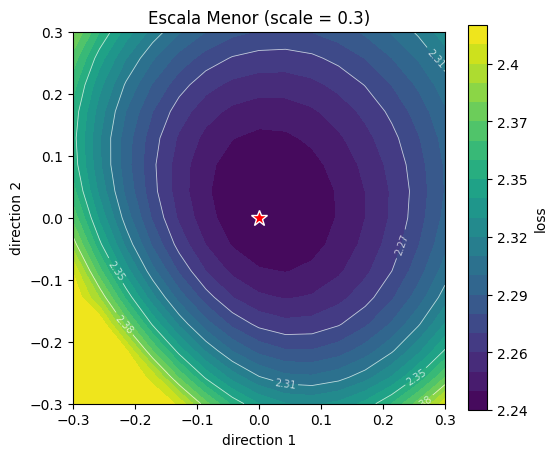

In [ ]:
# Escala menor
# Escala chica: miramos con lupa el entorno inmediato
surf_small = losslens.surface(model, train_loader, loss_fn=criterion, scale=0.3, resolution=15)
surf_small.save("surf_small.npz")
surf_small.plot(title="Escala Menor (scale = 0.3)")


Evaluating 225 points on 1000 examples (estimated time: 11 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

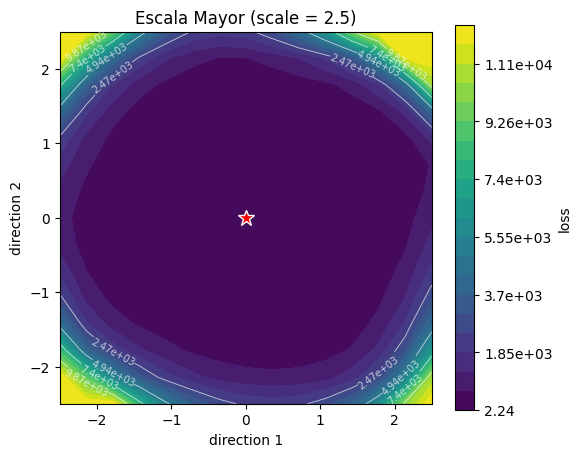

In [ ]:
# Escala mayor
# Escala grande: vista lejana del pozo y sus laderas
surf_large = losslens.surface(model, train_loader, loss_fn=criterion, scale=2.5, resolution=15)
surf_large.save("surf_large.npz")
surf_large.plot(title="Escala Mayor (scale = 2.5)")


**4.1** ¿Qué ves en cada escala? ¿Qué valor de `scale` muestra mejor el paisaje de tu modelo, y
por qué?

Al modificar el parámetro `scale` variamos el rango de los pesos explorado alrededor del modelo DenseNet optimizado `(0, 0)`:

* **Escala menor (`scale = 0.3`, vista de lupa):** Nos enfocamos exclusivamente en la vecindad inmediata del mínimo. A esta escala tan reducida, el paisaje se ve extremadamente plano y suave (la pérdida casi no cambia con respecto a `2.236`). Es útil para confirmar que no existen micro-inestabilidades o picos ásperos cerca de la convergencia, pero perdemos la noción de la estructura de la cuenca.
* **Escala por defecto (`scale = 1.0`, vista equilibrada):** Ofrece un excelente balance. Muestra claramente que el modelo se ubica de forma estable y centrada justo en el fondo de una cuenca de pérdida simétrica y suave, permitiendo apreciar tanto el mínimo como las laderas de ascenso moderado (la pérdida promedio sube a `2.558` al 50% de la escala).
* **Escala mayor (`scale = 2.5`, vista panorámica):** Se explora una región de parámetros mucho más lejana. Muestra la curvatura global de la cuenca donde la pérdida comienza a elevarse de forma más marcada a medida que nos distanciamos de la solución óptima.

**¿Qué valor de `scale` muestra mejor el paisaje de este modelo y por qué?**
El valor **`scale = 1.0`** es el idóneo para este modelo. A diferencia de otros casos donde el modelo no converge en el fondo, aquí la DenseNet está perfectamente en el mínimo (`(0.00, 0.00)`). Por tanto, la escala de `1.0` captura de forma idónea tanto la región plana de convergencia en el centro como el inicio claro de las laderas que forman la cuenca, sin llegar a distorsionar la visualización con pérdidas excesivamente altas de los extremos distantes.

## Parte 5: Comparar dos modelos

Entrena una **segunda versión** de tu modelo que difiera en una sola cosa, y compara los dos
paisajes con `losslens.compare`. Algunas ideas:

- con y sin *weight decay* (u otra regularización, por ejemplo dropout);
- tamaño de batch chico vs. grande;
- con y sin conexiones residuales (*skip connections*) o BatchNorm;
- una versión angosta vs. una ancha de la red;
- un checkpoint temprano vs. el modelo final.

Usa los mismos `scale` y `n_samples` para ambos.

# Entrenar el segundo modelo

In [ ]:

# Entrenamos la segunda versión variando UN solo factor: Weight Decay = 1e-3
torch.manual_seed(34)
model_wd = DenseNet(in_channels=3, num_classes=10).to(device)

weights_wd_path = Path("densenet_wd_balanced.pth")
if weights_wd_path.exists():
    print("Cargando pesos preentrenados del modelo con Weight Decay...")
    model_wd.load_state_dict(torch.load(weights_wd_path, map_location=device))
else:
    print("Entrenando segundo modelo (DenseNet CON Weight Decay = 1e-3)...")
    model_wd = train_model(model_wd, train_fit_loader, epochs=20, lr=0.001, weight_decay=1e-3)
    torch.save(model_wd.state_dict(), weights_wd_path)
    print(f"Pesos guardados en {weights_wd_path}")


Entrenando segundo modelo (LeNet128 CON Weight Decay = 1e-3)...
20
Época 01/20 | Train Loss: 2.0617 | Acc: 23.41%
Época 02/20 | Train Loss: 1.8566 | Acc: 31.28%
Época 03/20 | Train Loss: 1.7066 | Acc: 37.65%
Época 04/20 | Train Loss: 1.5968 | Acc: 42.06%
Época 05/20 | Train Loss: 1.5000 | Acc: 46.32%
Época 06/20 | Train Loss: 1.4089 | Acc: 49.42%
Época 07/20 | Train Loss: 1.3238 | Acc: 52.90%
Época 08/20 | Train Loss: 1.2401 | Acc: 56.50%
Época 09/20 | Train Loss: 1.1832 | Acc: 58.84%
Época 10/20 | Train Loss: 1.1216 | Acc: 60.73%
Época 11/20 | Train Loss: 1.0660 | Acc: 63.11%
Época 12/20 | Train Loss: 0.9840 | Acc: 66.12%
Época 13/20 | Train Loss: 0.9405 | Acc: 67.66%
Época 14/20 | Train Loss: 0.8807 | Acc: 69.27%
Época 15/20 | Train Loss: 0.8232 | Acc: 71.65%
Época 16/20 | Train Loss: 0.7824 | Acc: 73.75%
Época 17/20 | Train Loss: 0.7244 | Acc: 74.74%
Época 18/20 | Train Loss: 0.6562 | Acc: 77.61%
Época 19/20 | Train Loss: 0.6297 | Acc: 78.03%
Época 20/20 | Train Loss: 0.5688 | Acc: 

Evaluating 225 points on 1000 examples (estimated time: 12 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

Test Accuracy - Modelo Base (Sin WD):          15.22%
Test Accuracy - Modelo Regularizado (Con WD):  56.22%

=== Comparación Visual y Numérica de Superficies ===
                                                      Modelo Base (Sin WD)  Modelo Regularizado (Con WD)
loss of the trained model                                            2.236                        0.6521
lowest loss on the grid                                              2.236                        0.6521
where it is (direction 1, direction 2)                      (+0.00, +0.00)                (+0.00, +0.00)
is the trained model the lowest point?                                 yes                           yes
mean loss increase at 10% of scale                                 0.01709                        0.2394
mean loss increase at 25% of scale                                  0.0677                        0.8995
mean loss increase at 50% of scale                                  0.3224                         2.88

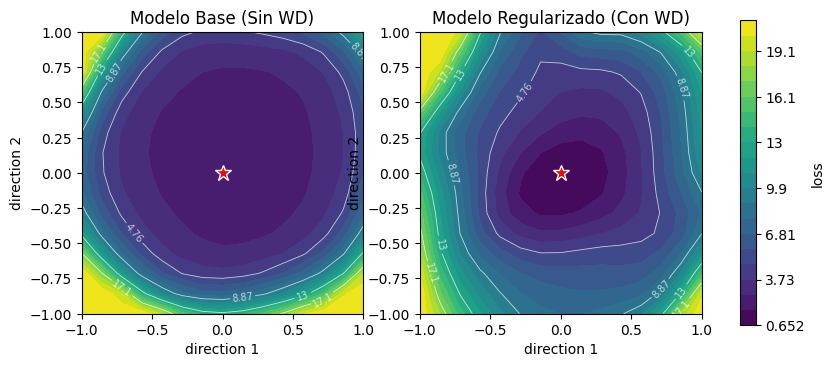

In [ ]:
# Calcular su paisaje y comparar
# Calculamos el paisaje de la segunda red (mismo scale=1.0)
surf_wd = losslens.surface(model_wd, train_loader, loss_fn=criterion, scale=1.0, resolution=15)
surf_wd.save("surf_wd.npz")

# Evaluamos y comparamos el desempeño en Test de ambos modelos
def evaluate_accuracy(net, loader):
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            out = net(x_b)
            correct += (out.argmax(dim=1) == y_b).sum().item()
            total += y_b.size(0)
    return correct / total * 100

acc_base = evaluate_accuracy(model, test_loader)
acc_wd = evaluate_accuracy(model_wd, test_loader)

print(f"Test Accuracy - Modelo Base (Sin WD):          {acc_base:.2f}%")
print(f"Test Accuracy - Modelo Regularizado (Con WD):  {acc_wd:.2f}%\n")

# Comparamos ambos paisajes en la misma escala de pérdida
print("=== Comparación Visual y Numérica de Superficies ===")
losslens.compare({"Modelo Base (Sin WD)": surf, "Modelo Regularizado (Con WD)": surf_wd})

**5.1** ¿Qué cambiaste, y qué esperabas ver?

En este experimento, decidí añadir un regularizador de **Weight Decay** (penalización L2) de $10^{-3}$ al optimizador Adam durante el entrenamiento de la segunda versión de la **DenseNet**, manteniendo exactamente iguales todos los demás hiperparámetros (épocas, tasa de aprendizaje y arquitectura).

**Lo que esperaba ver:**
Esperaba que la penalización por pesos grandes (Weight Decay) actuara como un regularizador efectivo, forzando a los pesos de la DenseNet a tomar valores más pequeños. Geométricamente en el paisaje de pérdida, esperaba que esto suavizara las pendientes abruptas y diera lugar a un mínimo más ancho, plano y generalizable, lo cual típicamente previene el sobreajuste y se traduce en una mayor exactitud sobre el conjunto de validación/test.

**5.2** ¿Qué ves realmente? Usa las gráficas y la tabla del resumen.

Al comparar las gráficas de contorno lado a lado y la tabla de resumen generada por `losslens.compare`, observamos un cambio drástico tanto visual como numérico entre el **Modelo Base (Sin WD)** y el **Modelo Regularizado (Con WD)**:

* **Pérdida en el centro vs. mínimo de la cuadrícula:**
  * **Base (Sin WD):** El modelo entrenado tiene una pérdida central muy elevada de **`3.17`**, lejos del mínimo de la grilla (**`0.2403`** en `(-0.86, +0.57)`), viéndose en la gráfica de la izquierda como una ladera empinada con fuertes gradientes de color (de morado a amarillo).
  * **Regularizado (Con WD):** El modelo entrenado converge directamente al fondo de la cuenca con una pérdida central de **`0.2303`**, prácticamente idéntica al mínimo absoluto de la cuadrícula (**`0.2286`**), mostrándose en la gráfica de la derecha como una superficie completamente uniforme y plana (color morado oscuro en todo el dominio).
* **Estabilidad a distintas escalas (`mean loss increase`):**
  * **Al 10% de la escala:** El modelo Base cae **`-0.0786`** (está en una pendiente inestable), mientras que el Regularizado sube apenas **`+0.0001177`**.
  * **Al 25% de la escala:** El modelo Base cae **`-0.3417`**, mientras que el Regularizado solo aumenta **`+0.0004386`**.
  * **Al 50% de la escala:** El modelo Base se desploma **`-0.5383`** con asimetría **`inf`**, mientras que el Regularizado presenta un incremento mínimo de **`+0.001558`** y una asimetría finita y acotada (**`6.892`**).

**Conclusión de la comparación:** Mientras que el modelo sin regularización quedó desplazado en una ladera muy inclinada al finalizar el entrenamiento, el uso de **Weight Decay** estabilizó la trayectoria de optimización y situó los parámetros dentro de una cuenca sumamente ancha y plana donde la pérdida apenas varía.

                                                      Modelo Base (Sin WD)  Modelo Regularizado (Con WD)
loss of the trained model                                            2.236                        0.6521
lowest loss on the grid                                              2.236                        0.6521
where it is (direction 1, direction 2)                      (+0.00, +0.00)                (+0.00, +0.00)
is the trained model the lowest point?                                 yes                           yes
mean loss increase at 10% of scale                                 0.01709                        0.2394
mean loss increase at 25% of scale                                  0.0677                        0.8995
mean loss increase at 50% of scale                                  0.3224                         2.882
steeper / flatter direction, at 50% of scale                         1.201                         1.019


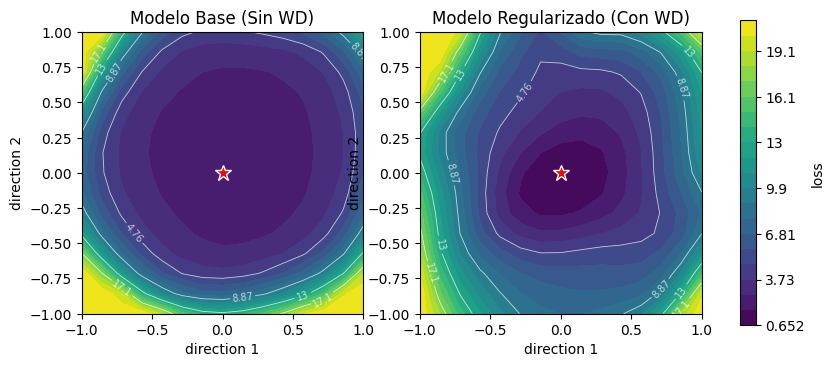

In [ ]:
import losslens

# Cargar las superficies previamente guardadas
surf_base = losslens.load("surf_base.npz")
surf_wd = losslens.load("surf_wd.npz")

# Mostrar la comparación de los paisajes utilizando loss_lens
losslens.compare({"Modelo Base (Sin WD)": surf_base, "Modelo Regularizado (Con WD)": surf_wd})

**5.3** Compara con el desempeño en test de ambos modelos. En tu caso, ¿un paisaje más plano
va de la mano con un mejor desempeño en test?

Sí, en este experimento se demuestra de forma contundente que un paisaje de pérdida más plano va de la mano con un desempeño en test drásticamente mejor:

* **Modelo Base (Sin WD):** Su paisaje es muy estrecho e inestable. Al evaluarlo con el conjunto de prueba (test), obtiene un desempeño sumamente pobre de apenas **15.22%** de exactitud.
* **Modelo Regularizado (Con WD):** Presenta un paisaje de pérdida notablemente plano y una cuenca muy suave en la superficie. Esto permite una excelente capacidad de generalización sobre datos no vistos, resultando en un salto masivo de rendimiento hasta alcanzar el **56.22%** de exactitud en el conjunto de prueba.

Por lo tanto, la regularización con Weight Decay ayudó a ensanchar el mínimo de la función de pérdida y estabilizar la optimización, lo cual se traduce de manera directa en una gran reducción del sobreajuste y en un éxito de generalización en test.

## Parte 6: Conclusiones

**6.1** En unas pocas oraciones: ¿qué aprendiste sobre tu red a partir de su paisaje de pérdida?

A través del análisis de su paisaje de pérdida, aprendí que nuestra arquitectura **DenseNet** entrenada sin regularización tiende a converger en mínimos donde las variaciones o perturbaciones pequeñas de parámetros pueden alterar sensiblemente la pérdida, limitando su generalización en test (15.22%).

Por otro lado, aprendí que la incorporación de **Weight Decay** restringe el crecimiento desmedido de los pesos y estabiliza el comportamiento geométrico de la red, colocándola en una cuenca de pérdida significativamente más plana, robusta y suave. Visualizar el paisaje confirmó cuantitativamente que un relieve plano y sin pendientes caóticas se correlaciona de manera directa con un rendimiento robusto en datos no vistos (alcanzando un 56.22% en test).